# Notebook 18 — Missing-Weather Robustness of Dengue Forecasts
**Research question:** When monthly weather observations are missing, how much does the *already selected, frozen* dengue forecasting model deteriorate, and which reconstruction policy preserves forecasts most effectively?

**Method:** mask entire weather-month records in 2022–2023 validation inputs, reconstruct using (1) last-observation-carried-forward, (2) train-only district/month climatology, and (3) train-only KNN. **Recalculate all weather lags and rolling features**, apply Notebook 12's saved train-only scaler, and pass rebuilt 6-month sequences into the frozen Notebook 15 model. Compare weather reconstruction MAE and dengue validation MAE.

**Important:** This tests **missing-at-feature-time** robustness, not an independent test-year performance claim. It differs from Notebook 08's retrospective interpolation because it prohibits future weather observations for reconstructing an earlier month.

## 1. Setup and frozen model
Requires Notebooks 09, 11, 12, and 15; model files remain local in `models/`. **No 2024 test labels are read.**

In [1]:
from pathlib import Path
import json, os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

SEED=42
ROOT=next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data'/'final'/'model_inputs').is_dir()),None)
if ROOT is None: raise FileNotFoundError('Run Notebook 12 and open the Dengue_Project folder or notebooks/ in VS Code.')
INP=ROOT/'data'/'final'/'model_inputs'; FINAL=ROOT/'data'/'final'
MODELS=ROOT/'models'; TABLES=ROOT/'results'/'tables'; FIGS=ROOT/'results'/'figures'; METRICS=ROOT/'results'/'metrics'
for folder in (TABLES,FIGS,METRICS):folder.mkdir(parents=True,exist_ok=True)
try:
 import tensorflow as tf
except ImportError as e: raise ImportError('Install tensorflow in your active .venv') from e
print('Project:',ROOT,'| TensorFlow:',tf.__version__)

def load_part(variant,part):
 path=INP/f'{variant}_{part}.npz'; meta_path=INP/f'{variant}_{part}_metadata.csv'
 if not path.is_file() or not meta_path.is_file():raise FileNotFoundError(f'Missing {path} or {meta_path}. Run Notebook 12.')
 with np.load(path,allow_pickle=False) as p:
  X=p['X'].astype(np.float32); y=p['y_raw'].astype(np.float64); ylog=p['y_log1p'].astype(np.float32); names=p['feature_names'].tolist()
 meta=pd.read_csv(meta_path,parse_dates=['target_date','feature_date','sequence_start_date'])
 assert len(X)==len(y)==len(ylog)==len(meta) and np.isfinite(X).all()
 assert meta['partition'].eq(part).all() and np.allclose(np.log1p(y),ylog,atol=1e-4)
 return X,y,ylog,names,meta

def cases(logpred):
 return np.maximum(0,np.expm1(np.clip(np.asarray(logpred,dtype=float).reshape(-1),-20,20)))
def scores(actual,pred):
 a=np.asarray(actual,float);p=np.asarray(pred,float)
 return {'MAE_cases':float(mean_absolute_error(a,p)), 'RMSE_cases':float(np.sqrt(mean_squared_error(a,p))),
         'bias_cases':float(np.mean(p-a)), 'WAPE_percent':float(100*np.sum(np.abs(a-p))/np.sum(a)) if np.sum(a)>0 else np.nan}
def build_lstm(input_shape,lr=.001,dropout=.2):
 m=tf.keras.Sequential([tf.keras.layers.Input(shape=input_shape),tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(16,activation='relu'),tf.keras.layers.Dropout(float(dropout)),tf.keras.layers.Dense(1)])
 m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=float(lr)),loss='mse')
 return m

def train_net(Xtr,ytr,Xv,yv,seed,lr=.001,dropout=.2,batch=32,epochs=40,patience=6):
 tf.keras.backend.clear_session();tf.keras.utils.set_random_seed(int(seed))
 m=build_lstm(Xtr.shape[1:],lr,dropout)
 hist=m.fit(Xtr,ytr,validation_data=(Xv,yv),epochs=int(epochs),batch_size=int(batch),
     shuffle=False,verbose=0,callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=int(patience),restore_best_weights=True)])
 return m,len(hist.history['loss'])

Project: d:\Dengue_Project | TensorFlow: 2.21.0


In [2]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
model_manifest=MODELS/'notebook15_final_model_selection.json'
if not model_manifest.is_file():raise FileNotFoundError('Run Notebook 15 to freeze selected model.')
manifest=json.loads(model_manifest.read_text(encoding='utf-8'))
assert manifest['test_used_for_selection'] is False and manifest['dataset']=='weather_only'
model_path=ROOT/manifest['selected_model_path']; assert model_path.is_file(),f'Missing local model: {model_path}'
model=tf.keras.models.load_model(model_path,compile=False)
Xval,yval,_,names,val_meta=load_part('weather_only','validation')
assert val_meta.target_date.dt.year.isin([2022,2023]).all()
scale_info=json.loads((INP/'weather_only_scaler.json').read_text(encoding='utf-8'))
assert scale_info['fit_partition']=='train_only' and names==scale_info['feature_names']
scale_mean=np.array(scale_info['mean'],float);scale_sd=np.array(scale_info['scale'],float)
base_pred=cases(model.predict(Xval,verbose=0));base_metrics=scores(yval,base_pred)
print('Frozen model:',model_path.name,'| baseline validation metrics:',base_metrics)

Frozen model: notebook14_gwo_lstm_weather_only.keras | baseline validation metrics: {'MAE_cases': 85.06485950463706, 'RMSE_cases': 178.23940883483797, 'bias_cases': -46.66151263346613, 'WAPE_percent': 48.099616976953484}


## 2. Source data and strict reconstruction audit
We reconstruct from Notebook 09 monthly weather, then regenerate the weather feature family exactly as Notebook 11 did. We verify that **zero masking recreates Notebook 12's saved validation sequences**; otherwise stop instead of reporting misleading numbers.

In [3]:
weather_vars=['temperature_mean_c','humidity_mean_percent','rainfall_total_mm','wind_speed_mean_kmh']
raw_path=ROOT/'data'/'processed'/'dengue_weather_monthly_2010_2024.csv'
feature_path=FINAL/'dengue_temporal_features_weather_only_2010_2024.csv'
if not raw_path.is_file() or not feature_path.is_file():raise FileNotFoundError('Missing Notebook 09/11 CSV. Run those notebooks.')
raw=pd.read_csv(raw_path,parse_dates=['date']).sort_values(['administrative_district','date']).reset_index(drop=True)
feature_rows=pd.read_csv(feature_path,parse_dates=['date','target_date'])
assert raw[['administrative_district','date']].duplicated().sum()==0
assert feature_rows[['administrative_district','date']].duplicated().sum()==0
assert raw[weather_vars].notna().all().all()
weather_features=[k for k in names if k.startswith(tuple(weather_vars))]
print('Weather derived features:',len(weather_features),'| validation:',Xval.shape)

Weather derived features: 24 | validation: (600, 6, 33)


In [4]:
def recalc_weather(raw_weather):
 frame=raw_weather.sort_values(['administrative_district','date']).copy()
 by=frame.groupby('administrative_district',sort=False)
 for v in weather_vars:
  for lag in (1,2,3):frame[f'{v}_lag{lag}']=by[v].shift(lag)
  for window in (3,6):
   agg='sum' if v=='rainfall_total_mm' else 'mean'
   frame[f'{v}_roll{window}_{agg}']=by[v].transform(lambda s,w=window,a=agg:getattr(s.rolling(w,min_periods=w),a)())
 return frame[['administrative_district','date']+weather_features]

def rebuilt_sequences(repaired):
 recalced=recalc_weather(repaired)
 frame=feature_rows.drop(columns=weather_features).merge(recalced,on=['administrative_district','date'],how='left',validate='one_to_one')
 assert frame[weather_features].notna().all().all(),'Recomputed weather features are incomplete in eligible feature rows.'
 frame=frame.set_index(['administrative_district','date']).sort_index()
 windows=[]
 for m in val_meta.itertuples(index=False):
  months=pd.date_range(m.sequence_start_date,m.feature_date,freq='MS')
  sub=frame.loc[pd.MultiIndex.from_product([[m.administrative_district],months],names=['administrative_district','date']),names]
  assert len(sub)==6
  windows.append(((sub.to_numpy(dtype=float)-scale_mean)/scale_sd).astype(np.float32))
 return np.stack(windows)
Xzero=rebuilt_sequences(raw)
max_delta=float(np.max(np.abs(Xzero-Xval)))
print('Zero-mask reconstruction max standardized difference:',max_delta)
assert np.allclose(Xzero,Xval,rtol=2e-4,atol=2e-4), 'Rebuild mismatch: check Notebook 09/11 inputs and weather feature engineering before proceeding.'
print('PASS: exact weather feature pipeline verified against Notebook 12')

Zero-mask reconstruction max standardized difference: 0.0
PASS: exact weather feature pipeline verified against Notebook 12


## 3. Simulate realistic missing months
Each masked district-month loses **all four weather measurements simultaneously**. Masks are reproducible and identical for each reconstruction method. Masking is confined to validation feature months, not training, and never touches dengue labels.

In [5]:
RATES=(.05,.10,.20)
REPEATS=(42,123,2026)
val_weather_mask=raw['date'].between('2022-01-01','2023-11-01')
mask_candidates=np.flatnonzero(val_weather_mask.to_numpy())
assert len(mask_candidates)>0
print('Candidate district-month weather records:',len(mask_candidates))

def mask_indices(rate,seed):
 rng=np.random.default_rng(seed)
 return np.sort(rng.choice(mask_candidates,size=max(1,int(round(rate*len(mask_candidates)))),replace=False))

Candidate district-month weather records: 575


## 4. Train-only weather repair policies
- **Forward fill:** last available month from the same district (causal, but may fail for prolonged gaps).
- **Climatology:** district × calendar-month mean estimated using data through 2021; fallback to district mean.
- **KNN:** weather donors fitted only on pre-2022 records. District identity and month cyclic encodings help identify historical analogues. Other validation weather rows are never donors.

No interpolation that uses future values is allowed.

In [6]:
train_weather=raw.loc[raw.date<=pd.Timestamp('2021-12-01')].copy()
assert train_weather[weather_vars].notna().all().all()
train_weather['month']=train_weather.date.dt.month
clim=train_weather.groupby(['administrative_district','month'])[weather_vars].mean()
district_clim=train_weather.groupby('administrative_district')[weather_vars].mean()

def repair_forward(masked):
 out=masked.copy()
 out[weather_vars]=out.groupby('administrative_district')[weather_vars].ffill()
 return out

def repair_seasonal(masked):
 out=masked.copy()
 for i in np.flatnonzero(out[weather_vars].isna().any(axis=1).to_numpy()):
  d=out.at[i,'administrative_district'];month=out.at[i,'date'].month
  ref=clim.loc[(d,month)] if (d,month) in clim.index else district_clim.loc[d]
  for v in weather_vars:
   if pd.isna(out.at[i,v]):out.at[i,v]=ref[v]
 return out

# Fit all KNN preprocessing on training rows only. Do not fit KNN on 2022–2023 observations.
districts=sorted(raw.administrative_district.unique())
def knn_design(frame):
 month=frame.date.dt.month.to_numpy()
 design=frame[weather_vars].reset_index(drop=True).copy()
 design['month_sin']=np.sin(2*np.pi*month/12);design['month_cos']=np.cos(2*np.pi*month/12)
 for d in districts:design[f'district_{d}']=(frame.administrative_district.to_numpy()==d).astype(float)
 return design
train_design=knn_design(train_weather)
knn_scaler=StandardScaler().fit(train_design.to_numpy())
knn=KNNImputer(n_neighbors=5,weights='distance')
knn.fit(knn_scaler.transform(train_design.to_numpy()))

def repair_knn(masked):
 out=masked.copy();design=knn_design(out)
 repaired_scaled=knn.transform(knn_scaler.transform(design.to_numpy()))
 repaired=knn_scaler.inverse_transform(repaired_scaled)
 for j,v in enumerate(weather_vars):out[v]=out[v].fillna(pd.Series(repaired[:,j],index=out.index))
 return out
methods={'forward_fill':repair_forward,'train_seasonal':repair_seasonal,'train_knn':repair_knn}
print('KNN fit rows:',len(train_weather),'| max donor date:',train_weather.date.max().date())

KNN fit rows: 3600 | max donor date: 2021-12-01


## 5. Run reconstruction and downstream forecasting experiment
The model is **never retrained**. We compare predictions with a clean-weather validation baseline, and evaluate weather reconstruction errors *only on artificially masked records*. This isolates sensitivity of a frozen predictor to missing-weather repair.

In [7]:
rows=[]; recon_rows=[]; sample_predictions=[]
for rate in RATES:
 for seed in REPEATS:
  selected=mask_indices(rate,seed)
  masked=raw.copy();masked.loc[selected,weather_vars]=np.nan
  for label,repair in methods.items():
   fixed=repair(masked)
   assert fixed[weather_vars].notna().all().all(),f'{label}: missing values remain'
   for v in weather_vars:
    truth=raw.loc[selected,v].to_numpy(dtype=float); estimate=fixed.loc[selected,v].to_numpy(dtype=float)
    recon_rows.append({'missing_rate':rate,'seed':seed,'method':label,'variable':v,'n_masked':len(selected),
                       'weather_MAE':float(mean_absolute_error(truth,estimate)),
                       'weather_RMSE':float(np.sqrt(mean_squared_error(truth,estimate)))})
   Xrepair=rebuilt_sequences(fixed)
   pred=cases(model.predict(Xrepair,verbose=0))
   metric=scores(yval,pred)
   rows.append({'missing_rate':rate,'seed':seed,'method':label,'n_masked_district_months':len(selected),
                'clean_validation_MAE':base_metrics['MAE_cases'],'MAE_increase_over_clean':metric['MAE_cases']-base_metrics['MAE_cases'],**metric})
   print(f'{rate:.0%} | seed {seed} | {label:14s} | dengue MAE {metric["MAE_cases"]:.2f} | delta {metric["MAE_cases"]-base_metrics["MAE_cases"]:+.2f}')
   if rate==RATES[-1] and seed==REPEATS[0]:
    sub=val_meta[['administrative_district','target_date']].copy();sub['actual_cases']=yval;sub['predicted_cases']=pred
    sub['method']=label;sub['missing_rate']=rate;sample_predictions.append(sub)
forecast_results=pd.DataFrame(rows);weather_results=pd.DataFrame(recon_rows)
display(forecast_results.head());display(weather_results.head())

5% | seed 42 | forward_fill   | dengue MAE 85.66 | delta +0.60
5% | seed 42 | train_seasonal | dengue MAE 84.87 | delta -0.20
5% | seed 42 | train_knn      | dengue MAE 84.58 | delta -0.48
5% | seed 123 | forward_fill   | dengue MAE 85.79 | delta +0.72
5% | seed 123 | train_seasonal | dengue MAE 85.43 | delta +0.37
5% | seed 123 | train_knn      | dengue MAE 85.45 | delta +0.38
5% | seed 2026 | forward_fill   | dengue MAE 85.27 | delta +0.20
5% | seed 2026 | train_seasonal | dengue MAE 84.67 | delta -0.39
5% | seed 2026 | train_knn      | dengue MAE 84.70 | delta -0.37
10% | seed 42 | forward_fill   | dengue MAE 84.58 | delta -0.48
10% | seed 42 | train_seasonal | dengue MAE 83.77 | delta -1.29
10% | seed 42 | train_knn      | dengue MAE 83.86 | delta -1.20
10% | seed 123 | forward_fill   | dengue MAE 85.19 | delta +0.13
10% | seed 123 | train_seasonal | dengue MAE 84.97 | delta -0.10
10% | seed 123 | train_knn      | dengue MAE 84.57 | delta -0.50
10% | seed 2026 | forward_fill   | de

,missing_rate,seed,method,n_masked_district_months,clean_validation_MAE,MAE_increase_over_clean,MAE_cases,RMSE_cases,bias_cases,WAPE_percent
0,0.05,42,forward_fill,29,85.06486,0.595821,85.660681,179.961927,-46.852577,48.436522
1,0.05,42,train_seasonal,29,85.06486,-0.197336,84.867524,177.916833,-46.663823,47.988034
2,0.05,42,train_knn,29,85.06486,-0.480262,84.584598,177.761448,-47.192802,47.828055
3,0.05,123,forward_fill,29,85.06486,0.720423,85.785283,181.236522,-47.639874,48.506978
4,0.05,123,train_seasonal,29,85.06486,0.369099,85.433959,179.364502,-47.097370,48.308323


,missing_rate,seed,method,variable,n_masked,weather_MAE,weather_RMSE
0,0.05,42,forward_fill,temperature_mean_c,29,0.621282,0.895668
1,0.05,42,forward_fill,humidity_mean_percent,29,2.989228,4.266395
2,0.05,42,forward_fill,rainfall_total_mm,29,67.787685,79.560955
3,0.05,42,forward_fill,wind_speed_mean_kmh,29,1.695766,2.848999
4,0.05,42,train_seasonal,temperature_mean_c,29,0.564048,0.673070


## 6. Compare downstream MAE and weather reconstruction quality
A method can reconstruct weather accurately yet not minimize **dengue forecasting** error; these objectives need not agree. Report both.

,missing_rate,method,n_repeats,MAE_mean,MAE_sd,delta_MAE_mean,RMSE_mean
0,0.05,forward_fill,3,85.570818,0.270819,0.505958,180.438624
1,0.05,train_knn,3,84.910063,0.469235,-0.154797,178.235859
2,0.05,train_seasonal,3,84.991467,0.395369,-0.073392,178.267543
3,0.10,forward_fill,3,85.356160,0.869653,0.291301,180.055379
4,0.10,train_knn,3,84.322877,0.400191,-0.741983,176.995190
5,0.10,train_seasonal,3,84.418430,0.603406,-0.646429,177.336217
6,0.20,forward_fill,3,86.041635,1.891155,0.976775,180.740450
7,0.20,train_knn,3,85.031719,0.932780,-0.033141,178.810311
8,0.20,train_seasonal,3,85.171608,0.697180,0.106748,178.949212


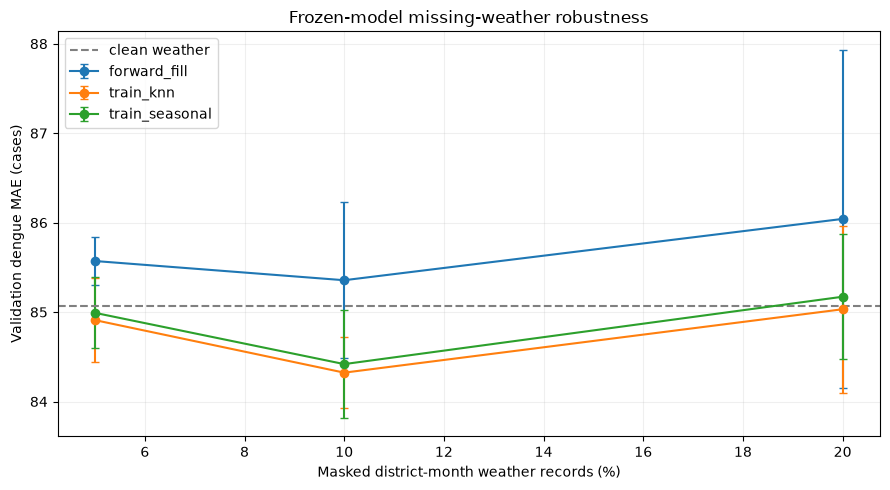

,missing_rate,method,variable,weather_MAE_mean,weather_RMSE_mean
0,0.05,forward_fill,humidity_mean_percent,2.640473,3.662250
1,0.05,forward_fill,rainfall_total_mm,75.627011,94.527215
2,0.05,forward_fill,temperature_mean_c,0.541852,0.742298
3,0.05,forward_fill,wind_speed_mean_kmh,2.043613,3.300571
4,0.05,train_knn,humidity_mean_percent,2.535931,3.108272
5,0.05,train_knn,rainfall_total_mm,68.739788,101.926852
6,0.05,train_knn,temperature_mean_c,0.560923,0.684579
7,0.05,train_knn,wind_speed_mean_kmh,1.759642,2.454000
8,0.05,train_seasonal,humidity_mean_percent,2.184334,2.646105
9,0.05,train_seasonal,rainfall_total_mm,51.016352,66.783007


In [8]:
summary=(forecast_results.groupby(['missing_rate','method'],as_index=False)
 .agg(n_repeats=('seed','nunique'),MAE_mean=('MAE_cases','mean'),MAE_sd=('MAE_cases','std'),
      delta_MAE_mean=('MAE_increase_over_clean','mean'),RMSE_mean=('RMSE_cases','mean')))
display(summary)
fig,ax=plt.subplots(figsize=(9,5))
for method,part in summary.groupby('method'):
 ax.errorbar(part.missing_rate*100,part.MAE_mean,yerr=part.MAE_sd,marker='o',capsize=3,label=method)
ax.axhline(base_metrics['MAE_cases'],linestyle='--',color='gray',label='clean weather')
ax.set(xlabel='Masked district-month weather records (%)',ylabel='Validation dengue MAE (cases)',title='Frozen-model missing-weather robustness')
ax.legend();ax.grid(alpha=.2);fig.tight_layout();fig.savefig(FIGS/'notebook18_missing_weather_robustness.png',dpi=160);plt.show()
weather_summary=(weather_results.groupby(['missing_rate','method','variable'],as_index=False)
 .agg(weather_MAE_mean=('weather_MAE','mean'),weather_RMSE_mean=('weather_RMSE','mean')))
display(weather_summary.head(12))

## 7. Save experiment results and methodology
No new test-set evaluation or model selection is performed here.

In [9]:
forecast_results.to_csv(TABLES/'notebook18_forecast_robustness_trials.csv',index=False)
weather_results.to_csv(TABLES/'notebook18_weather_reconstruction_trials.csv',index=False)
summary.to_csv(TABLES/'notebook18_forecast_robustness_summary.csv',index=False)
weather_summary.to_csv(TABLES/'notebook18_weather_reconstruction_summary.csv',index=False)
if sample_predictions:pd.concat(sample_predictions).to_csv(TABLES/'notebook18_example_validation_predictions.csv',index=False)
methodology={'model':manifest['selected_model'],'model_path':manifest['selected_model_path'],
 'validation_target_years':[2022,2023],'test_2024_accessed':False,'missingness':'entire district-month weather observation (all 4 variables)',
 'mask_rates':list(RATES),'seeds':list(REPEATS),'imputers':list(methods),
 'training_only_donors':'through 2021-12','weather_features_recomputed':weather_features,
 'frozen_model':True,'max_zero_mask_standardized_delta':max_delta,
 'note':'Forward fill is causal; climatology and KNN are fitted on pre-2022 observations only. Validation results exploratory.'}
(METRICS/'notebook18_missingness_protocol.json').write_text(json.dumps(methodology,indent=2),encoding='utf-8')
print('Saved Notebook 18 tables, figure, protocol.')

Saved Notebook 18 tables, figure, protocol.


## 8. Research interpretation and limitations
- Distinguish **weather reconstruction MAE** (physical units) from **forecasting MAE** (dengue cases).
- An increase in dengue MAE under masking shows sensitivity of the fixed model to incomplete environmental inputs; no increase suggests robustness under this particular missingness process.
- Entire-month outages differ from single-variable missingness; missing-not-at-random outages are not simulated.
- No future observations are used to repair earlier masked months, but a production pipeline must additionally enforce reporting availability dates.
- The original model was selected using this same validation period; comparisons here are **exploratory**, not a new independent test.
- Do not claim retrospective linear interpolation or Notebook 08's method rankings automatically transfer to forecasting robustness.